# Path distribution of the recorded trials

Probabilistic tube of the recorded paths of one task, built on the original recordings (filtered and resampled as in the reconstruction script), and position of a generated trajectory inside it.

1. Every trial is segmented at the same speed minima used to build the dataset (lognormal fit, strokes filtered by peak speed).
2. Inside every segment the trials are resampled at the same values of normalized arc length: corresponding points are compared regardless of timing.
3. At every point a Gaussian is estimated over the trials. Inside a segment the deviation is measured in the plane normal to the mean path (2 dof); at the junctions (speed minima) the full 3D covariance is used (3 dof).
4. Two coverages: **pointwise** (at every point the ellipse holds the chosen fraction of trials) and **whole path** (the chosen fraction of trials stays inside along the whole path), calibrated leave-one-out on the recorded trials.

In [15]:
import multiprocessing
import os
import pickle
import random
import sys
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

CUT_STRING = "src/master_thesis_data_analysis/data"
sys.path.append(os.path.join(os.getcwd().split(CUT_STRING)[0], CUT_STRING))
from framework import *
from framework.Spatial.BezierOptimization import BezierOptimization

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import yaml
from matplotlib import colors as mcolors
from matplotlib.lines import Line2D
from scipy.signal import find_peaks
from scipy.stats import chi2
from torch.distributions import Categorical

ROOT = os.getcwd().split("src")[0]
CSV_ROOT = os.path.join(ROOT, "recording_csv")
YAML_PATHS_FILE = os.path.join(ROOT, "src/unisa_acg_ros2/haptics/haptic_interaction_teach_and_record_demo/config/paths.yaml")
CKPT_PATH = "best_stroke_model_nll.pt"     # checkpoint saved by the network notebook

## Recorded trials

The segmentation repeats the steps of the reconstruction script with the same settings: Chebyshev II low-pass filter, resampling, speed minima, lognormal least-squares fit and strokes filtered by peak speed. A trial is kept only if the number of kept strokes equals the number of segments of the task, as in the dataset.

In [16]:
# ---- segmentation: same settings used to build reconstructed_csv ----
POSITION_COLUMNS = ["position_x", "position_y", "position_z"]
VELOCITY_COLUMNS = ["twist_linear_x", "twist_linear_y", "twist_linear_z"]
FILTER_ORDER = 11
FILTER_CUTOFF_HZ = 16
FILTER_STOPBAND_DB = 80
TARGET_FREQUENCY = 500      # Hz
LOCK_D_TO_GEOMETRY = True
TIME_DISTANCE = .1          # s
PROMINENCE = .005           # m/s
VEL_THRESHOLD = 0.2         # m/s

# ---- waypoints: normalized -> device frame, then expressed from the first waypoint (as in the network notebook) ----
WS_MIN = np.array([-0.082, -0.065, -0.085])
WS_MAX = np.array([0.082, 0.065, 0.085])


def waypoints_to_array(waypoints, swap_yz=False, ws_min=WS_MIN, ws_max=WS_MAX):
    """Convert the list of {'x','y','z'} dicts (normalized) into an Nx3 array in device coordinates."""
    arr = np.array([[w["x"], w["y"], w["z"]] for w in waypoints], dtype=float)
    if swap_yz:
        arr[:, [1, 2]] = arr[:, [2, 1]]
    if ws_min is not None and ws_max is not None:
        ws_min = np.asarray(ws_min, dtype=float)
        ws_max = np.asarray(ws_max, dtype=float)
        arr = ws_min + arr * (ws_max - ws_min)
    return arr


with open(YAML_PATHS_FILE, "r") as f:
    WAYPOINTS_BY_TASK = {path["name"]: waypoints_to_array(path["waypoints"]) for path in yaml.safe_load(f)["paths"]}
WAYPOINTS_BY_TASK = {task: waypoints - waypoints[0] for task, waypoints in WAYPOINTS_BY_TASK.items()}

# ---- tube ----
TASK = "LETTER_N"
N_SEGMENTS = len(WAYPOINTS_BY_TASK[TASK]) - 1
N_POINTS = 60               # samples per segment, equally spaced in normalized arc length
COVERAGE = 0.95             # fraction of the recorded behaviour inside the tube
COV_FLOOR = 1e-4            # m: isotropic standard deviation added to every covariance (resolution of the positions)
RING_STEP = 6               # one cross-section ellipse every RING_STEP samples in the plots
N_WORKERS = max(1, (os.cpu_count() or 2) - 1)
CACHE_PATH = f"recorded_segments_{TASK}.pkl"    # delete it after changing the segmentation settings

In [17]:
def find_minima_maxima(speed:np.ndarray, samples_distance:float|None=None, prominence:float|None=None) -> tuple[list[int], list[int]]:
    """Find the indices of the speed minima and maxima in the given speed array."""
    # Find local maxima
    maxima_indices, _ = find_peaks(speed, distance=samples_distance, prominence=prominence)
    # Find local minima by inverting the speed
    minima_indices, _ = find_peaks(-speed, distance=samples_distance, prominence=prominence)
    try:
        if minima_indices[0] > maxima_indices[0]:
            if speed[0] < speed[maxima_indices[0]]:
                minima_indices = np.r_[0, minima_indices]
            else:
                if speed[0] > speed[minima_indices[0]]:
                    maxima_indices = np.r_[0, maxima_indices]
            
        if minima_indices[-1] < maxima_indices[-1]:
            if speed[-1] < speed[maxima_indices[-1]]:
                minima_indices = np.r_[minima_indices, speed.size - 1]
            else:
                if speed[-1] > speed[minima_indices[-1]]:
                    maxima_indices = np.r_[maxima_indices, speed.size - 1]
    except IndexError:
        if len(minima_indices) == 0 and len(maxima_indices) == 1:
            minima_indices = np.array([0, speed.size - 1])
    return minima_indices, maxima_indices # type: ignore


def segment_recording(file):
    """
    Recorded path of one trial between its first and last kept speed minima, segmented as in the
    reconstruction script. Returns (file, points [N, 3], junctions [N_SEGMENTS + 1] indices into points),
    or (file, None, reason) when the trial is discarded.
    """
    try:
        csv_data = pd.read_csv(file)
        csv_data["timestamp"] = (csv_data["timestamp"] - csv_data["timestamp"].iloc[0]) / 1e9
        recording = Recording(
            trajectory=Trajectory(
                vx=csv_data[VELOCITY_COLUMNS[0]].to_numpy(),
                vy=csv_data[VELOCITY_COLUMNS[1]].to_numpy(),
                vz=csv_data[VELOCITY_COLUMNS[2]].to_numpy(),
            ),
            curve=Curve(
                x=csv_data[POSITION_COLUMNS[0]].to_numpy(),
                y=csv_data[POSITION_COLUMNS[1]].to_numpy(),
                z=csv_data[POSITION_COLUMNS[2]].to_numpy(),
            ),
            t=csv_data["timestamp"].to_numpy(),
        )
        chebyshev = Chebyshev(order=FILTER_ORDER, cutoff=FILTER_CUTOFF_HZ, stopband_attenuation=FILTER_STOPBAND_DB)
        resampler = Resample(target_fs=TARGET_FREQUENCY)
        recording.trajectory = resampler.apply(chebyshev.apply(recording.trajectory))  # type: ignore
        recording.curve = resampler.apply(chebyshev.apply(recording.curve))            # type: ignore

        minima_idx, _ = find_minima_maxima(recording.trajectory.speed,
                                           samples_distance=int(TIME_DISTANCE * TARGET_FREQUENCY),
                                           prominence=PROMINENCE)
        ls = LeastSquares(lock_D=LOCK_D_TO_GEOMETRY, refine=False)
        ls.set_boundaries(minima_idx)
        strokes = ls.approximate(recording)

        # contiguous strokes whose peak speed reaches the threshold: one per segment of the task
        kept, _ = strokes.filter_strokes_by_peak(VEL_THRESHOLD)
        if len(kept) != N_SEGMENTS:
            return file, None, f"{len(kept)} kept strokes for {N_SEGMENTS} segments"

        # stroke k spans the window [minima[k], minima[k + 1]]
        first = strokes.index(kept[0])
        bounds = np.asarray(minima_idx[first:first + len(kept) + 1], dtype=int)
        points = np.asarray(recording.curve.points, dtype=float)[bounds[0]:bounds[-1] + 1]
        return file, points, bounds - bounds[0]
    except Exception as error:
        return file, None, f"error: {error}"

In [18]:
# Segmentation of every recording of the task (cached: the lognormal fit is the slow step)
files = [f for f in sorted(Path(CSV_ROOT).glob("**/*.csv")) if f.parts[-2] == TASK]

if os.path.exists(CACHE_PATH):
    with open(CACHE_PATH, "rb") as f:
        results = pickle.load(f)
elif N_WORKERS > 1:
    with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=multiprocessing.get_context("fork")) as pool:
        results = list(pool.map(segment_recording, files))
else:
    results = [segment_recording(f) for f in files]

if not os.path.exists(CACHE_PATH):
    with open(CACHE_PATH, "wb") as f:
        pickle.dump(results, f)

trials = [(Path(f), points, junctions) for f, points, junctions in results if points is not None]
rejected = [(Path(f), reason) for f, points, reason in results if points is None]
print(f"task {TASK}: {len(files)} recordings | kept {len(trials)} | discarded {len(rejected)}")
for f, reason in rejected:
    print(f"  {f.parts[-3]}/{f.name}: {reason}")

task LETTER_N: 102 recordings | kept 100 | discarded 2
  NOEMI_BIANCAMANO/recording_0.csv: 4 kept strokes for 3 segments
  NOEMI_BIANCAMANO/recording_17.csv: 4 kept strokes for 3 segments


## Alignment

Inside every segment (between two consecutive kept speed minima) a trial is resampled at `N_POINTS` values of normalized arc length $s \in [0, 1]$: the same $s$ of the same segment is the same point of the task in every trial, whatever the speed profile.

**Frame.** Every trial is translated so that it starts at the origin. This is the frame of the network: its waypoints are expressed from the first one and a generated chain starts there. As a consequence the tube has zero width at the start and opens along the path.

In [19]:
S_GRID = np.linspace(0.0, 1.0, N_POINTS)


def resample_segments(points, junctions, s_grid=S_GRID):
    """Points [n_segments, len(s_grid), 3] equally spaced in normalized arc length inside every segment."""
    segments = []
    for a, b in zip(junctions[:-1], junctions[1:]):
        segment = points[a:b + 1]
        arc = np.concatenate([[0.0], np.cumsum(np.linalg.norm(np.diff(segment, axis=0), axis=1))])
        if arc[-1] <= 0.0:
            raise ValueError("segment of zero length")
        segments.append(np.column_stack([np.interp(s_grid, arc / arc[-1], segment[:, d]) for d in range(3)]))
    return np.stack(segments)


aligned, trial_files = [], []
for f, points, junctions in trials:
    try:
        aligned.append(resample_segments(points, junctions))
        trial_files.append(f)
    except ValueError as error:
        print(f"skipped {f.parts[-3]}/{f.name}: {error}")

aligned = np.stack(aligned)                    # [n_trials, n_segments, N_POINTS, 3]
aligned -= aligned[:, :1, :1, :]               # every trial starts at the origin
n_trials = len(aligned)
print(f"aligned trials: {aligned.shape}")

aligned trials: (100, 3, 60, 3)


## Gaussian tube

Mean $m(s)$ and covariance $\Sigma(s)$ over the trials at every point (plus the floor `COV_FLOOR`). The deviation of a path $x$ is scored by its tail probability $p = P(\chi^2_\nu \ge d^2)$, with $d$ the Mahalanobis distance: in the plane normal to the mean path inside a segment ($\nu = 2$), in 3D at the junctions ($\nu = 3$). Low $p$ = far from the recorded trials.

* **Pointwise tube**: $p \ge 1 - \text{COVERAGE}$ at that point.
* **Whole-path tube**: $\min_s p \ge p^*$, where $p^*$ is the $(1 - \text{COVERAGE})$ quantile of $\min_s p$ over the recorded trials. Each recorded trial is scored against the statistics of the other trials (leave-one-out), so that it is out of sample like a generated trajectory.

In [20]:
IS_JUNCTION = np.zeros(N_POINTS, dtype=bool)
IS_JUNCTION[[0, -1]] = True
FLOOR = COV_FLOOR ** 2 * np.eye(3)


def path_tangents(path):
    """Unit tangent [n_segments, n_points, 3] of a path, segment by segment."""
    tangent = np.gradient(path, axis=1)
    return tangent / np.maximum(np.linalg.norm(tangent, axis=-1, keepdims=True), 1e-12)


def normal_bases(tangent):
    """Orthonormal basis [..., 3, 2] of the plane normal to every tangent [..., 3]."""
    helper = np.eye(3)[np.argmin(np.abs(tangent), axis=-1)]
    n1 = helper - np.sum(helper * tangent, axis=-1, keepdims=True) * tangent
    n1 /= np.linalg.norm(n1, axis=-1, keepdims=True)
    return np.stack([n1, np.cross(tangent, n1)], axis=-1)


def tail_probability(x, mean, cov, basis):
    """
    Tail probability of the Gaussian model at the path x: P(chi2 >= d^2), d = Mahalanobis distance.
    Inside a segment the deviation is measured in the plane normal to the mean path (2 dof),
    at the junctions with the full covariance (3 dof).
    Shapes: x, mean [..., S, P, 3]; cov [..., S, P, 3, 3]; basis [S, P, 3, 2] -> [..., S, P].
    """
    diff = x - mean
    d2_full = np.einsum("...i,...ij,...j->...", diff, np.linalg.inv(cov), diff)
    y = np.einsum("...ik,...i->...k", basis, diff)
    cov_plane = np.einsum("...ik,...ij,...jl->...kl", basis, cov, basis)
    d2_plane = np.einsum("...k,...kl,...l->...", y, np.linalg.inv(cov_plane), y)
    return np.where(IS_JUNCTION, chi2.sf(d2_full, 3), chi2.sf(d2_plane, 2))


assert n_trials >= 5, "too few trials to estimate a 3D covariance"

# statistics of all the recorded trials: the tube used for generated trajectories
mean_path = aligned.mean(axis=0)                                         # [S, P, 3]
deviation = aligned - mean_path                                          # [n, S, P, 3]
scatter = np.einsum("nspi,nspj->spij", deviation, deviation)             # [S, P, 3, 3]
cov_path = scatter / (n_trials - 1) + FLOOR
basis = normal_bases(path_tangents(mean_path))                           # [S, P, 3, 2]

# leave-one-out statistics of every trial, by downdating mean and scatter
loo_mean = mean_path - deviation / (n_trials - 1)
loo_cov = (scatter - n_trials / (n_trials - 1) * np.einsum("nspi,nspj->nspij", deviation, deviation)) / (n_trials - 2) + FLOOR
loo_tail = tail_probability(aligned, loo_mean, loo_cov, basis)           # [n, S, P]

trial_min_tail = loo_tail.reshape(n_trials, -1).min(axis=1)              # most extreme point of every trial
P_POINTWISE = 1.0 - COVERAGE
P_SIMULTANEOUS = float(np.quantile(trial_min_tail, 1.0 - COVERAGE))
print(f"pointwise threshold p >= {P_POINTWISE:.3g} | whole-path threshold min p >= {P_SIMULTANEOUS:.3g}")

pointwise threshold p >= 0.05 | whole-path threshold min p >= 0.00924


### Calibration of the Gaussian model

If the Gaussian describes the recorded spread, the leave-one-out tail probabilities are uniform on $[0, 1]$ and the pointwise tube holds `COVERAGE` of the trials at every point. An excess near $p = 0$ means heavy tails, outliers or several strategies (e.g. different ways of taking a corner); the right plot shows where along the path it happens.

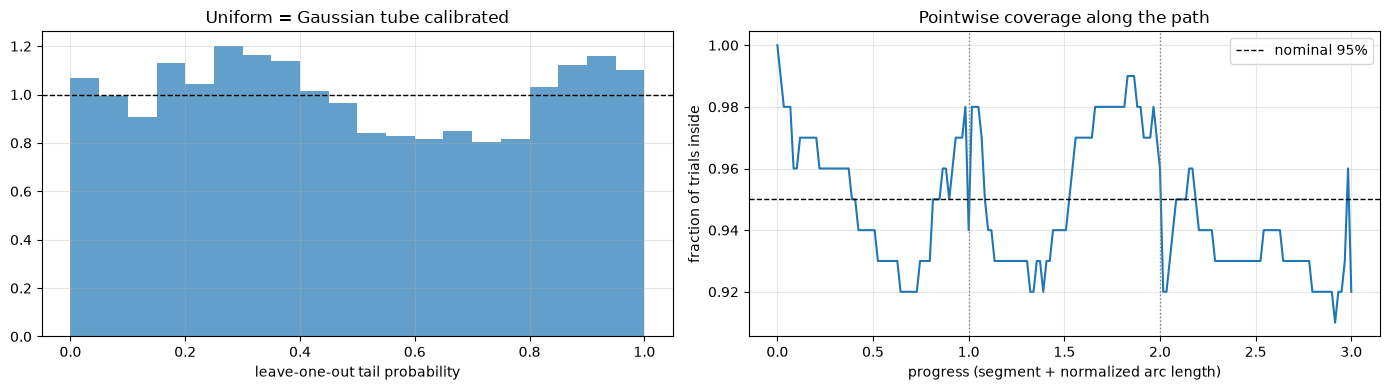

In [21]:
progress = np.arange(N_SEGMENTS)[:, None] + S_GRID[None, :]             # segment index + normalized arc length
not_origin = np.ones((N_SEGMENTS, N_POINTS), dtype=bool)
not_origin[0, 0] = False                                                 # every trial starts exactly there

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(loo_tail[:, not_origin].ravel(), bins=20, range=(0.0, 1.0), density=True, alpha=0.7)
axes[0].axhline(1.0, color="black", linestyle="--", linewidth=1)
axes[0].set_xlabel("leave-one-out tail probability")
axes[0].set_title("Uniform = Gaussian tube calibrated")

axes[1].plot(progress.ravel(), (loo_tail >= P_POINTWISE).mean(axis=0).ravel(), color="tab:blue")
axes[1].axhline(COVERAGE, color="black", linestyle="--", linewidth=1, label=f"nominal {COVERAGE:.0%}")
for k in range(1, N_SEGMENTS):
    axes[1].axvline(k, color="gray", linestyle=":", linewidth=1)
axes[1].set_xlabel("progress (segment + normalized arc length)")
axes[1].set_ylabel("fraction of trials inside")
axes[1].set_title("Pointwise coverage along the path")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
def set_axes_equal(ax, points, margin=0.05):
    """Give the 3D axes the same metric scale, centered on the given (N, 3) points."""
    mins, maxs = points.min(axis=0), points.max(axis=0)
    centers = (mins + maxs) / 2
    half_span = (maxs - mins).max() / 2 * (1 + margin)
    ax.set_xlim(centers[0] - half_span, centers[0] + half_span)
    ax.set_ylim(centers[1] - half_span, centers[1] + half_span)
    ax.set_zlim(centers[2] - half_span, centers[2] + half_span)
    ax.set_box_aspect((1, 1, 1))


def ellipse(center, basis, cov2, radius, n=64):
    """Points [n, dim] of {center + basis @ y : y^T cov2^-1 y = radius^2}; basis [dim, 2]."""
    w, v = np.linalg.eigh(cov2)
    angle = np.linspace(0.0, 2.0 * np.pi, n)
    y = v @ (np.sqrt(np.maximum(w, 0.0))[:, None] * radius * np.stack([np.cos(angle), np.sin(angle)]))
    return center + (basis @ y).T


def ellipsoid(center, cov, radius, n=16):
    """Wireframe grids (X, Y, Z) of {x : (x - center)^T cov^-1 (x - center) = radius^2}."""
    w, v = np.linalg.eigh(cov)
    u, phi = np.meshgrid(np.linspace(0.0, 2.0 * np.pi, n), np.linspace(0.0, np.pi, n // 2 + 1))
    sphere = np.stack([np.cos(u) * np.sin(phi), np.sin(u) * np.sin(phi), np.cos(phi)], axis=-1)
    points = center + radius * (sphere * np.sqrt(np.maximum(w, 0.0))) @ v.T
    return points[..., 0], points[..., 1], points[..., 2]


def tube_radii(p_level):
    """Mahalanobis radius of the tube at tail probability p_level: (normal plane, junction)."""
    return np.sqrt(chi2.isf(p_level, 2)), np.sqrt(chi2.isf(p_level, 3))


TAIL_NORM = mcolors.LogNorm(vmin=1e-6, vmax=1.0, clip=True)
TAIL_CMAP = "RdYlGn"


def plot_tube_3d(generated=None, generated_tail=None, p_level=None, title=""):
    """Recorded trials, mean path and tube (rings in the normal plane, ellipsoids at the junctions);
    a generated path is colored by its tail probability."""
    p_level = P_SIMULTANEOUS if p_level is None else p_level
    r_plane, r_junction = tube_radii(p_level)
    fig = plt.figure(figsize=(11, 9))
    ax = fig.add_subplot(projection="3d")

    for trial in aligned:
        ax.plot(*trial.reshape(-1, 3).T, color="gray", linewidth=0.6, alpha=0.25)
    ax.plot(*mean_path.reshape(-1, 3).T, color="black", linewidth=2)
    for k in range(N_SEGMENTS):
        for i in range(RING_STEP, N_POINTS - 1, RING_STEP):
            cov2 = basis[k, i].T @ cov_path[k, i] @ basis[k, i]
            ax.plot(*ellipse(mean_path[k, i], basis[k, i], cov2, r_plane).T, color="tab:blue", linewidth=0.8, alpha=0.6)
        ax.plot_wireframe(*ellipsoid(mean_path[k, -1], cov_path[k, -1], r_junction), color="tab:blue", linewidth=0.4, alpha=0.4)
    ax.plot(*WAYPOINTS_BY_TASK[TASK].T, "k--o", linewidth=1, markersize=5)

    shown = [aligned.reshape(-1, 3)]
    if generated is not None:
        path = generated.reshape(-1, 3)
        ax.plot(*path.T, color="black", linewidth=0.8)
        points = ax.scatter(*path.T, c=generated_tail.ravel(), cmap=TAIL_CMAP, norm=TAIL_NORM, s=12, depthshade=False)
        fig.colorbar(points, ax=ax, shrink=0.6, label="tail probability of the generated path")
        shown.append(path)

    handles = [
        Line2D([], [], color="gray", label="recorded trials"),
        Line2D([], [], color="black", linewidth=2, label="mean recorded path"),
        Line2D([], [], color="tab:blue", label=f"tube (p >= {p_level:.2g})"),
        Line2D([], [], color="black", linestyle="--", marker="o", label="waypoints"),
    ]
    ax.legend(handles=handles, loc="upper left")
    ax.set_xlabel("X [m]")
    ax.set_ylabel("Y [m]")
    ax.set_zlabel("Z [m]")
    ax.set_title(title)
    set_axes_equal(ax, np.vstack(shown))
    plt.tight_layout()
    plt.show()


def plot_tube_planes(generated=None, generated_tail=None, p_level=None, title=""):
    """The same tube projected on the XY, XZ and ZY planes."""
    p_level = P_SIMULTANEOUS if p_level is None else p_level
    r_plane, r_junction = tube_radii(p_level)
    planes = [(0, 1, "X", "Y"), (0, 2, "X", "Z"), (2, 1, "Z", "Y")]
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
    for ax, (i, j, xlabel, ylabel) in zip(axes, planes):
        for trial in aligned:
            ax.plot(trial[..., i].ravel(), trial[..., j].ravel(), color="gray", linewidth=0.6, alpha=0.25)
        for k in range(N_SEGMENTS):
            for n in range(RING_STEP, N_POINTS - 1, RING_STEP):
                cov2 = basis[k, n].T @ cov_path[k, n] @ basis[k, n]
                ring = ellipse(mean_path[k, n], basis[k, n], cov2, r_plane)
                ax.plot(ring[:, i], ring[:, j], color="tab:blue", linewidth=0.8, alpha=0.6)
            cov_ij = cov_path[k, -1][np.ix_([i, j], [i, j])]
            junction = ellipse(mean_path[k, -1, [i, j]], np.eye(2), cov_ij, r_junction)
            ax.plot(junction[:, 0], junction[:, 1], color="tab:blue", linewidth=1.2)
        ax.plot(mean_path[..., i].ravel(), mean_path[..., j].ravel(), color="black", linewidth=2)
        ax.plot(WAYPOINTS_BY_TASK[TASK][:, i], WAYPOINTS_BY_TASK[TASK][:, j], "k--o", linewidth=1, markersize=5)
        if generated is not None:
            ax.plot(generated[..., i].ravel(), generated[..., j].ravel(), color="black", linewidth=0.8)
            points = ax.scatter(generated[..., i].ravel(), generated[..., j].ravel(), c=generated_tail.ravel(),
                                cmap=TAIL_CMAP, norm=TAIL_NORM, s=12, zorder=4)
        ax.set_xlabel(f"{xlabel} [m]")
        ax.set_ylabel(f"{ylabel} [m]")
        ax.set_title(f"{xlabel}{ylabel} plane")
        ax.grid(alpha=0.3)
        ax.axis("equal")
    axes[1].invert_yaxis()
    axes[2].invert_xaxis()
    if generated is not None:
        fig.colorbar(points, ax=axes, shrink=0.8, label="tail probability of the generated path")
    fig.suptitle(title)
    plt.show()


def plot_profile(generated_tail=None, label="generated"):
    """Tail probability along the path: recorded trials (leave-one-out) and, optionally, a generated path."""
    x = progress.ravel()
    fig, ax = plt.subplots(figsize=(13, 4))
    for n, tail in enumerate(loo_tail):
        ax.plot(x, np.clip(tail.ravel(), 1e-12, 1.0), color="gray", linewidth=0.6, alpha=0.2,
                label="recorded trials (leave-one-out)" if n == 0 else None)
    if generated_tail is not None:
        ax.plot(x, np.clip(generated_tail.ravel(), 1e-12, 1.0), color="tab:red", linewidth=2, label=label)
    ax.axhline(P_POINTWISE, color="tab:blue", linestyle="--", label=f"pointwise {COVERAGE:.0%}")
    ax.axhline(P_SIMULTANEOUS, color="tab:blue", label=f"whole path {COVERAGE:.0%}")
    for k in range(1, N_SEGMENTS):
        ax.axvline(k, color="black", linestyle=":", linewidth=1)
    ax.set_yscale("log")
    ax.set_xlabel("progress (segment + normalized arc length); dotted lines = junctions")
    ax.set_ylabel("tail probability (low = far)")
    ax.grid(alpha=0.3)
    ax.legend(loc="lower left", fontsize=8)
    plt.tight_layout()
    plt.show()


def summarize(tail, label):
    """Fraction of the path inside the pointwise tube, whole-path verdict and empirical p-value."""
    min_tail = tail.min()
    p_value = np.mean(trial_min_tail <= min_tail)
    verdict = "inside" if min_tail >= P_SIMULTANEOUS else "outside"
    print(f"{label}: inside the pointwise tube on {np.mean(tail >= P_POINTWISE):.0%} of the path | "
          f"min tail probability {min_tail:.2e} -> {verdict} the whole-path {COVERAGE:.0%} tube | "
          f"recorded trials at least as extreme: {p_value:.0%}")

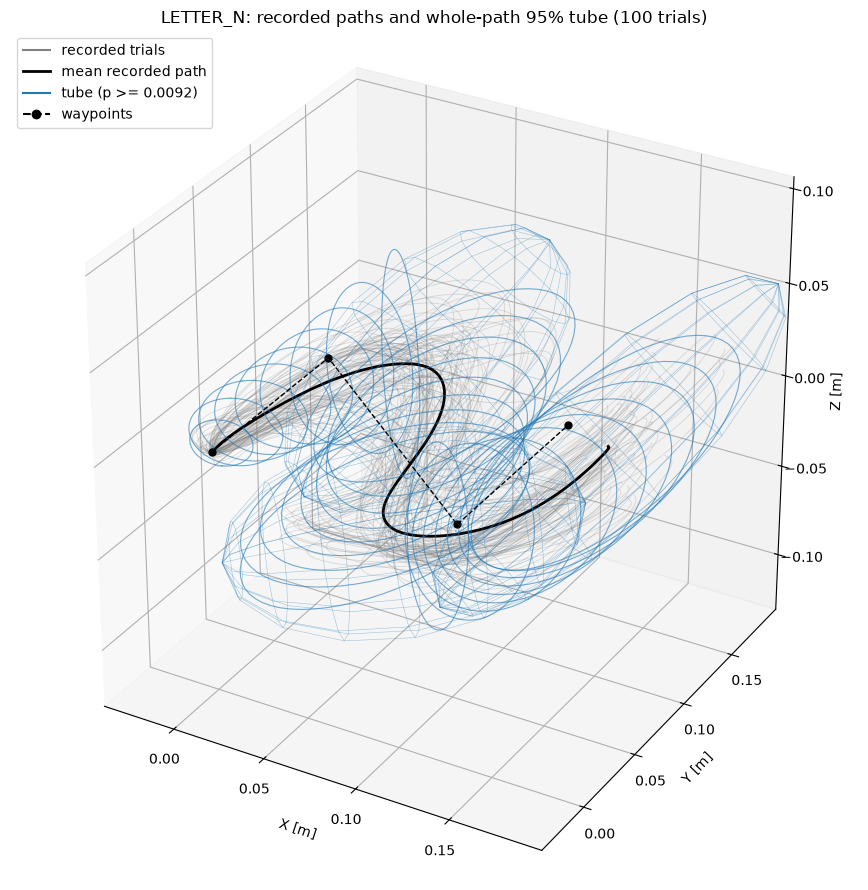

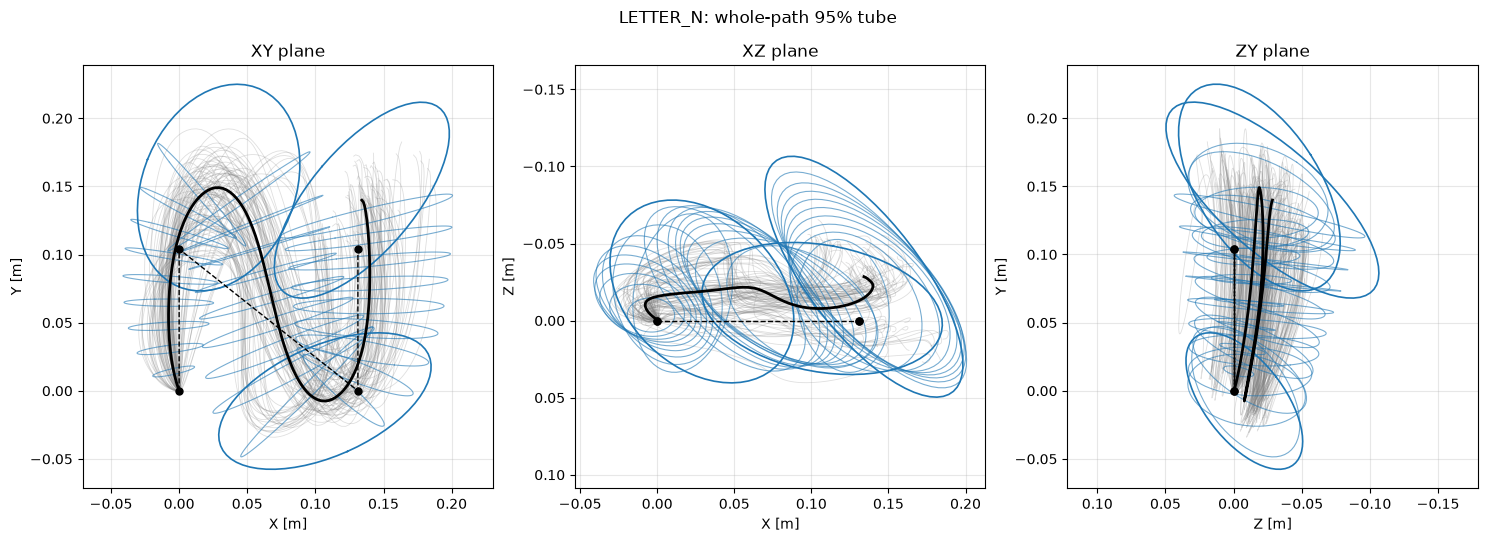

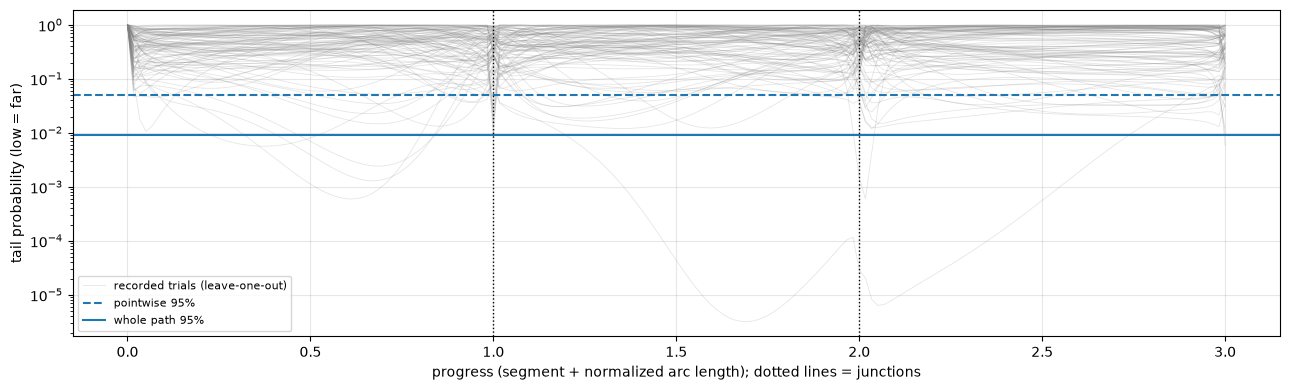

In [23]:
plot_tube_3d(title=f"{TASK}: recorded paths and whole-path {COVERAGE:.0%} tube ({n_trials} trials)")
plot_tube_planes(title=f"{TASK}: whole-path {COVERAGE:.0%} tube")
plot_profile()

## Generated trajectory

The model is loaded from the checkpoint of the network notebook; architecture, generation functions and conventions (`TARGET_KEYS`, `PREV_KEYS`, `WP_REFERENCE`) are the same. The generated Bézier chain starts at the first waypoint (the origin) and every stroke is sampled at the same normalized arc length as the recorded segments.

In [24]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---- network I/O definition: must match the checkpoint ----
T0_FIRST = 0.2
TARGET_KEYS = ["dt0", "mu", "sigma", "lambda_s", "u_s", "lambda_e", "u_e", "delta_p"]
DT0_INDEX = TARGET_KEYS.index("dt0")
PREV_KEYS = [f"prev_{k}" for k in TARGET_KEYS if k != "delta_p"]
WP_REFERENCE = "actual"      # conditioning frame used to build the dataset
LAMBDA_MIN = 1e-3
SIGMA_MIN = 1e-3

In [25]:
class MixtureDensityNetwork(nn.Module):
    """
    MDN head with Gaussian components, full (lower Cholesky factor) or diagonal covariance.
    Outputs: means [B, K, D], lower-triangular scale factors [B, K, D, D] (diagonal matrices for diagonal
    covariances), mixing logits [B, K].
    """

    def __init__(self, input_dim, output_dim, num_components, hidden_dim=128, min_diag=1e-3, covariance="full"):
        super().__init__()
        if covariance not in ("full", "diagonal"):
            raise ValueError("covariance must be 'full' or 'diagonal'")
        self.input_dim = input_dim
        self.output_dim = output_dim
        self.num_components = num_components
        self.hidden_dim = hidden_dim
        self.min_diag = min_diag
        self.covariance = covariance
        self.num_tril = output_dim * (output_dim + 1) // 2
        # raw scale outputs of one component: the Cholesky entries (row-major lower triangle) or the diagonal
        self.num_scale = self.num_tril if covariance == "full" else output_dim

        rows, cols = torch.tril_indices(output_dim, output_dim)
        self.register_buffer("tril_rows", rows, persistent=False)
        self.register_buffer("tril_cols", cols, persistent=False)
        self.register_buffer("diag_mask", rows == cols, persistent=False)

        self.hidden_layer = nn.Linear(input_dim, hidden_dim)
        self.weights_layer = nn.Linear(hidden_dim, num_components)  # mixing logits
        self.means_layer = nn.Linear(hidden_dim, num_components * output_dim)
        self.scale_layer = nn.Linear(hidden_dim, num_components * self.num_scale)

    def set_weights(self, target_samples: torch.Tensor, sigma_weight_scale: float = 0.1):
        """
        Initialization. `target_samples` [N, D] should already be standardized.
        Means are spread over the target range; each scale factor starts as diag(std_d)
        (zero off-diagonal entries for full covariances).
        """
        nn.init.kaiming_uniform_(self.hidden_layer.weight, nonlinearity="relu")
        nn.init.zeros_(self.hidden_layer.bias)

        nn.init.xavier_uniform_(self.weights_layer.weight)
        nn.init.xavier_uniform_(self.means_layer.weight)
        nn.init.xavier_uniform_(self.scale_layer.weight)

        t_min = target_samples.min(dim=0).values  # [D]
        t_max = target_samples.max(dim=0).values  # [D]
        mean_bias = torch.empty(self.num_components, self.output_dim)
        for k in range(self.num_components):
            mean_bias[k] = (t_min + (t_max - t_min) * (k + 0.5) / self.num_components).cpu()

        with torch.no_grad():
            self.means_layer.bias.copy_(mean_bias.reshape(-1))
            self.scale_layer.weight.mul_(sigma_weight_scale)

            # inverse softplus so that diag(L) starts at the per-dimension data std
            data_std = target_samples.std(dim=0).to(self.scale_layer.bias)
            init_diag = (data_std - self.min_diag).clamp_min(1e-3)
            raw_diag = torch.log(torch.expm1(init_diag))
            bias = torch.zeros(self.num_components, self.num_scale).to(self.scale_layer.bias)
            if self.covariance == "full":
                bias[:, self.diag_mask] = raw_diag
            else:
                bias[:] = raw_diag
            self.scale_layer.bias.copy_(bias.reshape(-1))

    def _build_scale_tril(self, raw: torch.Tensor) -> torch.Tensor:
        """raw [B, K, num_scale] -> lower-triangular L [B, K, D, D] with positive diagonal."""
        if self.covariance == "diagonal":
            return torch.diag_embed(F.softplus(raw) + self.min_diag)
        batch = raw.size(0)
        dim = self.output_dim
        tril = raw.new_zeros(batch, self.num_components, dim, dim)
        tril[..., self.tril_rows, self.tril_cols] = raw
        diag = F.softplus(tril.diagonal(dim1=-2, dim2=-1)) + self.min_diag
        return tril.tril(-1) + torch.diag_embed(diag)

    def forward(self, x: torch.Tensor):
        hidden = torch.relu(self.hidden_layer(x))
        mix_logits = self.weights_layer(hidden)
        means = self.means_layer(hidden).view(-1, self.num_components, self.output_dim)
        raw = self.scale_layer(hidden).view(-1, self.num_components, self.num_scale)
        return means, self._build_scale_tril(raw), mix_logits

In [26]:
class GenerativeModel(nn.Module):
    """Generative model of strokes: embeddings -> LSTM -> trunk -> MDN (full or diagonal covariance)."""

    def __init__(self, input_dim, LSTM_dim, LSTM_count, output_dim,
                 mixture_components, recur_dim=None, min_diag=1e-3, mdn_hidden_dim=128, covariance="full",
                 stateful=False):
        """
        mdn_hidden_dim: width of the hidden layer of the MDN head.
        covariance: "full" (lower Cholesky factor) or "diagonal" covariance of every mixture component.
        stateful: True carries the LSTM state along the strokes of a recording (training on whole recordings and
            autoregressive generation); False starts every stroke from the zero state.
        """
        super().__init__()
        # constructor arguments, stored in the checkpoints to rebuild the same model
        self.arch = dict(
            input_dim=input_dim, LSTM_dim=LSTM_dim, LSTM_count=LSTM_count,
            output_dim=output_dim, mixture_components=mixture_components, recur_dim=recur_dim, min_diag=min_diag,
            mdn_hidden_dim=mdn_hidden_dim, covariance=covariance, stateful=stateful,
        )
        self.input_dim = input_dim
        self.output_dim = output_dim
        self.lstm_dim = LSTM_dim
        self.lstm_count = LSTM_count
        self.mixture_components = mixture_components
        self.stateful = bool(stateful)
        # dimension of the previous-step vector (defaults to the target dimension)
        self.recur_dim = output_dim if recur_dim is None else recur_dim

        self.lstm = nn.LSTM(input_size=input_dim + self.recur_dim, hidden_size=LSTM_dim,
                            num_layers=LSTM_count, batch_first=True)
        self.trunk = nn.Linear(LSTM_dim, LSTM_dim)
        self.mdn = MixtureDensityNetwork(LSTM_dim, output_dim, num_components=mixture_components,
                                         hidden_dim=mdn_hidden_dim, min_diag=min_diag, covariance=covariance)

    def set_weights(self, target_samples, sigma_weight_scale=0.1):
        self.mdn.set_weights(target_samples, sigma_weight_scale)
        nn.init.kaiming_uniform_(self.trunk.weight, nonlinearity="relu")
        nn.init.zeros_(self.trunk.bias)

    def forward(self, x, prev_output=None, state=None, lengths=None, return_state=False):
        """
        Args:
            x: conditioning input [N, input_dim]
            prev_output: previous-step vector [N, recur_dim] (zeros embedding if None)
            state: LSTM state (h, c) at the start of the call; None = zero state
            lengths: number of strokes of each recording when the N rows are whole recordings stacked recording by
                recording in stroke order: the state then flows along every recording. None = every row is one
                step that starts from `state`.
        With stateful=False every row starts from the zero state and `state` / `lengths` are ignored.
        Returns:
            means [N, K, D], scale_tril [N, K, D, D], mix_logits [N, K] (+ final state if requested)
        """
        # Embed the input and previous output
        input_embedded = x
        if prev_output is not None:
            prev_embedded = prev_output
        else:
            prev_embedded = torch.zeros_like(input_embedded)
        features = torch.cat((input_embedded, prev_embedded), dim=-1)          # [N, 2E]

        if self.stateful and lengths is not None:
            # [B, T, 2E], padded at the end: the outputs of the real steps do not depend on the padding
            steps = nn.utils.rnn.pad_sequence(torch.split(features, list(lengths)), batch_first=True)
            lstm_out, new_state = self.lstm(steps, state)
            valid = (torch.arange(steps.size(1), device=features.device)[None, :]
                     < torch.as_tensor(lengths, device=features.device)[:, None])
            hidden = lstm_out[valid]                                            # [N, H], same row order as x
        else:
            lstm_out, new_state = self.lstm(features.unsqueeze(1), state if self.stateful else None)
            hidden = lstm_out.squeeze(1)
        trunk_out = torch.relu(self.trunk(hidden))

        means, scale_tril, mix_logits = self.mdn(trunk_out)
        if return_state:
            return means, scale_tril, mix_logits, new_state
        return means, scale_tril, mix_logits

    @torch.no_grad()
    def sample(self, x, prev_output=None, state=None, deterministic=False):
        """One step for every row: (sample [B, D], LSTM state to pass to the next step)."""
        means, scale_tril, mix_logits, new_state = self.forward(x, prev_output, state, return_state=True)
        batch_idx = torch.arange(means.size(0), device=means.device)

        if deterministic:
            return means[batch_idx, mix_logits.argmax(dim=-1)], new_state

        comp_idx = Categorical(logits=mix_logits).sample()
        sel_mean = means[batch_idx, comp_idx]          # [B, D]
        sel_tril = scale_tril[batch_idx, comp_idx]     # [B, D, D]
        eps = torch.randn_like(sel_mean)
        return sel_mean + (sel_tril @ eps.unsqueeze(-1)).squeeze(-1), new_state

In [27]:
def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def _standardize(x, stat, device):
    m, s = stat
    x = x.float().to(device).reshape(x.size(0), -1)
    return (x - m.to(device)) / s.to(device)


def stroke_deltas(task, stroke_number, start):
    """Waypoint vectors seen by stroke k, in a frame whose origin is the start of the stroke.

    wp   = W[k+1] - start   waypoint the stroke is aiming at
    wp_n = W[k+2] - start   the following waypoint (W[k+1] again if W[k+1] is the last one)
    """
    waypoints = WAYPOINTS_BY_TASK[task]
    last = len(waypoints) - 1
    k = int(stroke_number)
    wp = waypoints[min(k + 1, last)] - start
    wp_n = waypoints[min(k + 2, last)] - start
    return wp.astype(np.float32), wp_n.astype(np.float32)


def _unit(v):
    v = np.asarray(v, dtype=float)
    return v / max(np.linalg.norm(v), 1e-8)


def sample_stroke(model, stats, task, k, start, prev, state=None, deterministic=False):
    """
    One autoregressive step. `start` conditions wp / wp_n (as in training); `prev` is the previous stroke or None;
    `state` is the LSTM state after the previous stroke (None at the start). Returns (stroke, new state).
    """
    wp, wp_n = stroke_deltas(task, k, start)
    is_first = torch.full((1, 1), 1.0 if prev is None else 0.0, device=device)
    x = torch.cat([
        _standardize(torch.from_numpy(wp)[None], stats["wp"], device),
        _standardize(torch.from_numpy(wp_n)[None], stats["wp_n"], device),
        is_first,
    ], dim=-1)

    if prev is None:
        prev_vec = torch.zeros(1, RECUR_DIM, device=device)      # start-of-sequence input, as in training
    else:
        prev_vec = torch.cat([
            _standardize(
                torch.as_tensor(np.asarray(prev[key[len("prev_"):]], dtype=np.float32)).reshape(1, -1),
                stats[key[len("prev_"):]], device)
            for key in PREV_KEYS
        ], dim=-1)

    out, state = model.sample(x, prev_output=prev_vec, state=state, deterministic=deterministic)
    out = out.cpu()                                               # [1, OUTPUT_DIM], standardized

    params, i = {}, 0
    for key in TARGET_KEYS:
        mean, std = stats[key][0].cpu(), stats[key][1].cpu()
        d = mean.numel()
        params[key] = (out[:, i:i + d] * std + mean).numpy()[0]
        i += d

    # the network is Gaussian on R^n: project the samples back on the valid set;
    # the delay of the first stroke is the constant T0_FIRST (that output is not trained)
    return {
        "dt0": T0_FIRST if prev is None else float(params["dt0"][0]),
        "mu": float(params["mu"][0]),
        "sigma": max(float(params["sigma"][0]), SIGMA_MIN),
        "lambda_s": max(float(params["lambda_s"][0]), LAMBDA_MIN),
        "u_s": _unit(params["u_s"]),
        "lambda_e": max(float(params["lambda_e"][0]), LAMBDA_MIN),
        "u_e": _unit(params["u_e"]),
        "delta_p": params["delta_p"].astype(np.float64),
    }, state


@torch.no_grad()
def generate_task(model, stats, task, seed, n_strokes=None, wp_reference=WP_REFERENCE, deterministic=False):
    """All the stroke parameters needed to execute `task`, for a given seed."""
    if task not in WAYPOINTS_BY_TASK:
        raise KeyError(f"unknown task '{task}'. Available: {sorted(WAYPOINTS_BY_TASK)}")
    waypoints = WAYPOINTS_BY_TASK[task]
    n_strokes = len(waypoints) - 1 if n_strokes is None else int(n_strokes)

    set_seed(seed)
    model.eval()
    strokes, prev, state = [], None, None
    chain = waypoints[0].astype(np.float64)          # where the previous stroke ended
    onset = 0.0                                      # absolute onset of the current stroke: cumulative sum of dt0
    for k in range(n_strokes):
        # conditioning frame: same convention used to build the dataset
        start = chain if wp_reference == "actual" else waypoints[min(k, len(waypoints) - 1)].astype(np.float64)
        stroke, state = sample_stroke(model, stats, task, k, start, prev, state=state, deterministic=deterministic)
        onset += stroke["dt0"]
        stroke["t0"] = onset
        stroke["stroke_number"] = k
        stroke["p0"] = chain.copy()
        stroke["p3"] = chain + stroke["delta_p"]
        chain = stroke["p3"]
        strokes.append(stroke)
        prev = stroke
    return strokes


def load_checkpoint(path):
    """-> (model in eval mode, stats, checkpoint dict)."""
    ckpt = torch.load(path, map_location=device, weights_only=False)
    if ckpt["target_keys"] != list(TARGET_KEYS) or ckpt["prev_keys"] != list(PREV_KEYS):
        raise ValueError("the checkpoint was trained with different TARGET_KEYS / PREV_KEYS")
    model = GenerativeModel(**ckpt["config"]).to(device)
    model.load_state_dict(ckpt["model_state"])
    model.eval()
    return model, ckpt["stats"], ckpt

In [28]:
model, stats, ckpt = load_checkpoint(CKPT_PATH)
RECUR_DIM = ckpt["config"]["recur_dim"]
print(f"checkpoint: loss {ckpt['loss']} | epoch {ckpt['epoch']} | validation NLL {ckpt['val_nll']:.4f}")

checkpoint: loss nll | epoch 648 | validation NLL 2.0175


generated, seed 25: inside the pointwise tube on 91% of the path | min tail probability 4.01e-05 -> outside the whole-path 95% tube | recorded trials at least as extreme: 1%


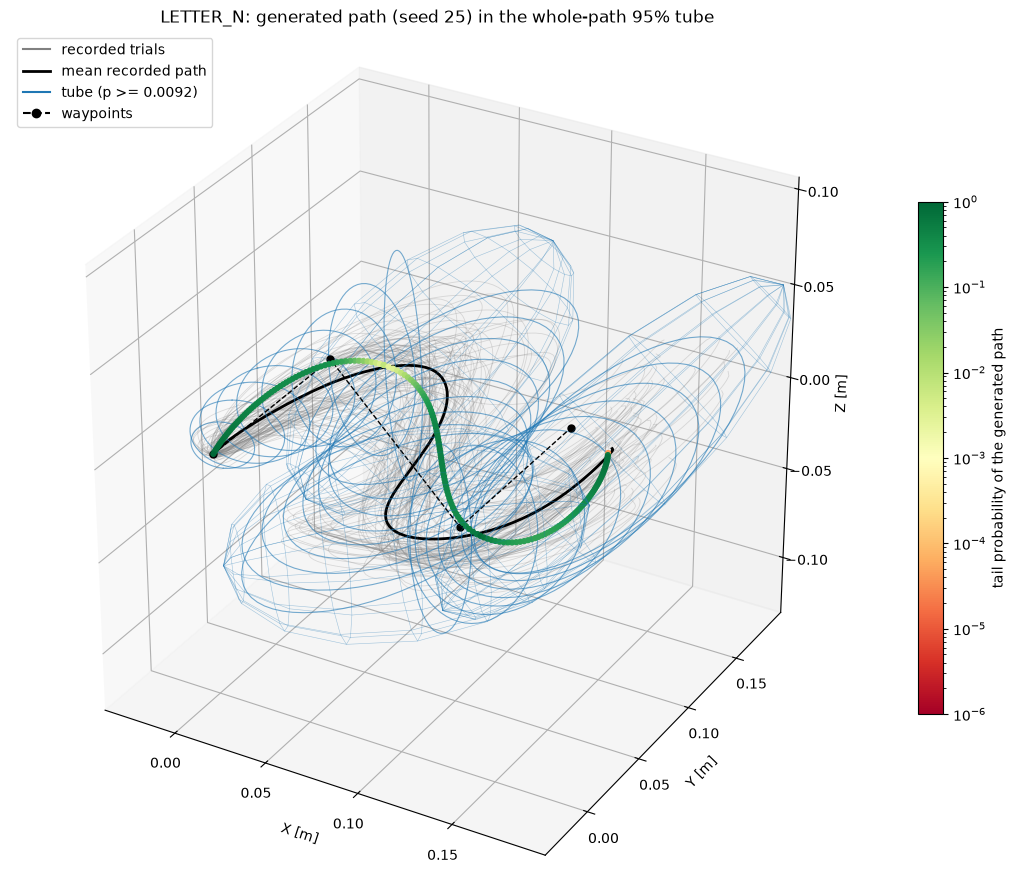

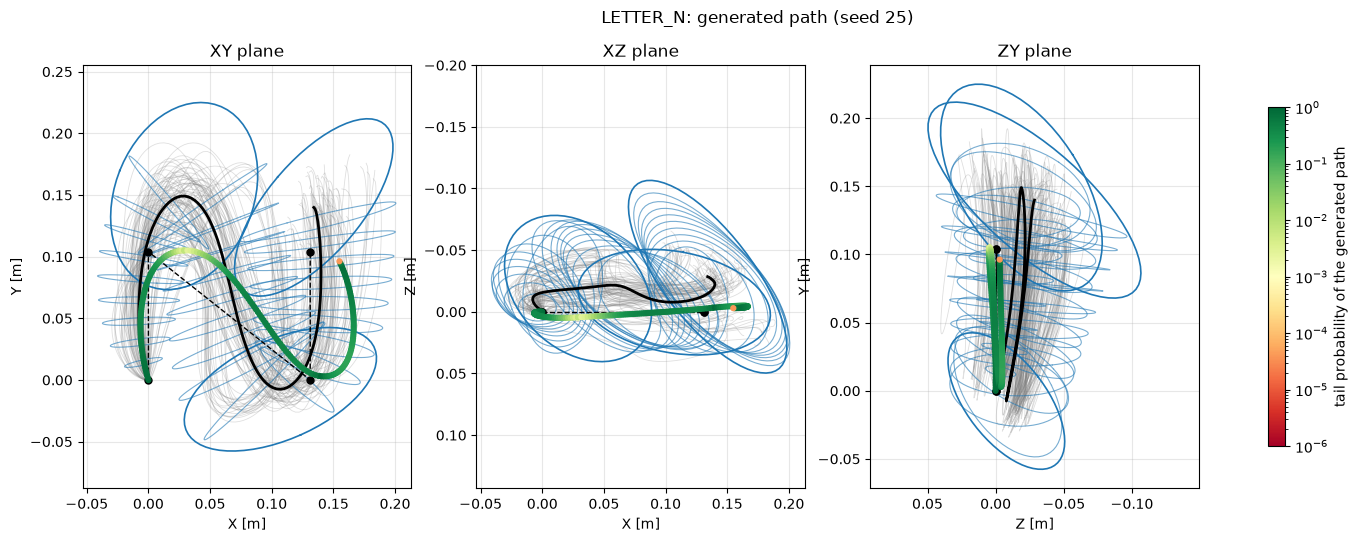

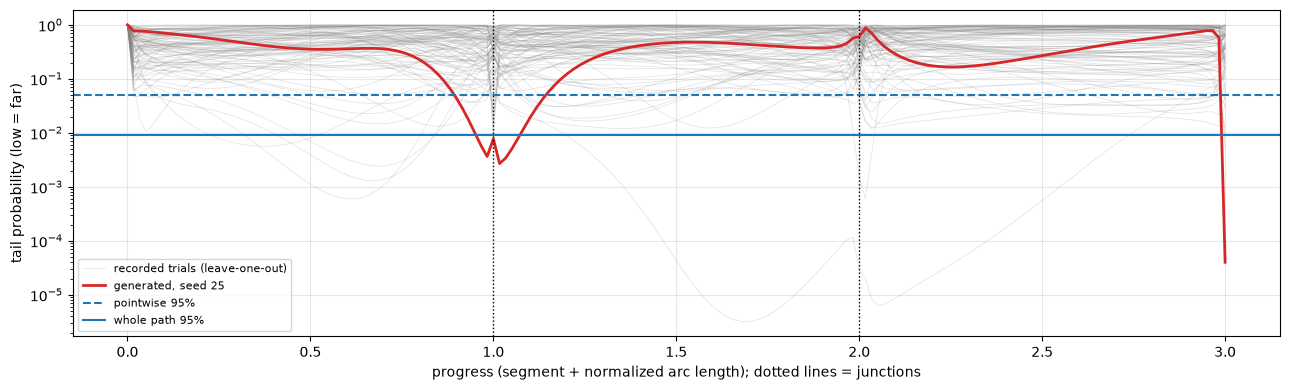

In [32]:
GEN_SEED = 25


def generated_segments(strokes, s_grid=S_GRID):
    """Path [n_segments, len(s_grid), 3] of a generated stroke sequence, equally spaced in normalized arc length inside every stroke."""
    segments = []
    for s in strokes:
        geometry = (s["lambda_s"], s["lambda_e"], s["p0"], s["p3"], s["u_s"], s["u_e"])
        segments.append(BezierOptimization._bezier(BezierOptimization._arclength_parameters(s_grid, *geometry), *geometry))
    return np.stack(segments)


generated = generated_segments(generate_task(model, stats, TASK, GEN_SEED, deterministic=True))
generated_tail = tail_probability(generated, mean_path, cov_path, basis)

summarize(generated_tail, f"generated, seed {GEN_SEED}")
plot_tube_3d(generated, generated_tail, title=f"{TASK}: generated path (seed {GEN_SEED}) in the whole-path {COVERAGE:.0%} tube")
plot_tube_planes(generated, generated_tail, title=f"{TASK}: generated path (seed {GEN_SEED})")
plot_profile(generated_tail, label=f"generated, seed {GEN_SEED}")

### Many generated trajectories

If the generator reproduces the recorded spread, about `COVERAGE` of its paths fall inside the whole-path tube and the distribution of their most extreme point matches the recorded one. Many more inside and shifted to the right = less variable than the recorded trials; many outside = more variable or biased.

generated paths inside the whole-path 95% tube: 2% of 100 (recorded, leave-one-out: 95%)


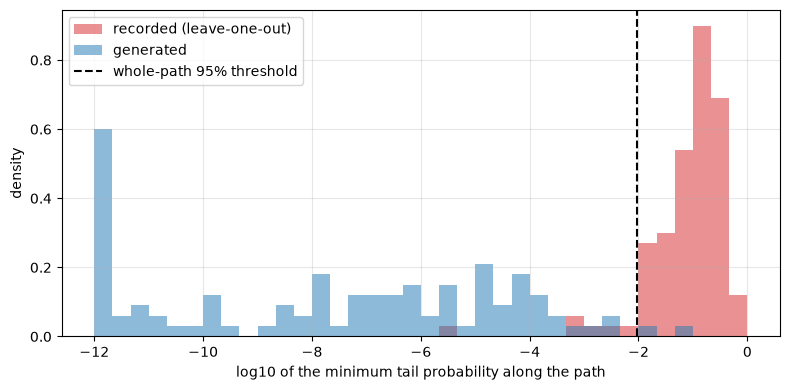

In [33]:
N_GENERATED = 100

gen_min_tail, failed = [], 0
for seed in range(N_GENERATED):
    try:
        path = generated_segments(generate_task(model, stats, TASK, seed))
    except Exception:          # degenerate sampled geometry
        failed += 1
        continue
    gen_min_tail.append(tail_probability(path, mean_path, cov_path, basis).min())
gen_min_tail = np.asarray(gen_min_tail)

print(f"generated paths inside the whole-path {COVERAGE:.0%} tube: {np.mean(gen_min_tail >= P_SIMULTANEOUS):.0%} "
      f"of {len(gen_min_tail)} (recorded, leave-one-out: {np.mean(trial_min_tail >= P_SIMULTANEOUS):.0%})"
      + (f" | failed: {failed}" if failed else ""))

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(-12, 0, 37)
ax.hist(np.log10(np.clip(trial_min_tail, 1e-12, 1.0)), bins=bins, density=True, alpha=0.5, color="tab:red", label="recorded (leave-one-out)")
ax.hist(np.log10(np.clip(gen_min_tail, 1e-12, 1.0)), bins=bins, density=True, alpha=0.5, color="tab:blue", label="generated")
ax.axvline(np.log10(P_SIMULTANEOUS), color="black", linestyle="--", label=f"whole-path {COVERAGE:.0%} threshold")
ax.set_xlabel("log10 of the minimum tail probability along the path")
ax.set_ylabel("density")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## Interactive export (Plotly)

One self-contained HTML file (Plotly embedded, it opens offline) with the 3D scene and the profile along the path. Clicking a legend entry hides or shows a group; hovering a recorded trial shows its subject and recording, so the most atypical trials can be identified.

In [ ]:
import plotly.graph_objects as go

EXPORT_PATH = f"path_tube_{TASK}_seed_{GEN_SEED}.html"
N_RING = 40                                   # points of every cross-section ellipse of the exported tube
TUBE_COLOR = "rgb(31, 119, 180)"
SHOW_JUNCTIONS = True                         # initial state of the ellipsoids at the speed minima (toggled from the legend)


def transported_bases(path):
    """
    Orthonormal bases [n_segments, n_points, 3, 2] of the planes normal to the path. Inside every segment the
    first normal is carried from one point to the next by projecting it on the next plane, so consecutive
    cross-sections are parametrized without twist.
    """
    tangent = path_tangents(path)
    bases = np.empty(path.shape + (2,))
    for k in range(path.shape[0]):
        n1 = normal_bases(tangent[k, 0])[:, 0]
        for i in range(path.shape[1]):
            t = tangent[k, i]
            n1 = n1 - np.dot(n1, t) * t
            n1 /= np.linalg.norm(n1)
            bases[k, i] = np.column_stack([n1, np.cross(t, n1)])
    return bases


def tube_surface(k, radius, frames):
    """Grids (X, Y, Z) of the tube of segment k at a Mahalanobis radius, junctions excluded:
    ring i is {m_i + B_i L_i radius c(theta)}, with L_i the Cholesky factor of the normal-plane covariance."""
    theta = np.linspace(0.0, 2.0 * np.pi, N_RING + 1)
    circle = np.stack([np.cos(theta), np.sin(theta)])
    rings = []
    for i in range(1, N_POINTS - 1):
        frame = frames[k, i]
        chol = np.linalg.cholesky(frame.T @ cov_path[k, i] @ frame)
        rings.append(mean_path[k, i] + (frame @ (radius * chol @ circle)).T)
    rings = np.stack(rings)
    return rings[..., 0], rings[..., 1], rings[..., 2]


def plotly_tube(generated=None, generated_tail=None, p_level=None, title="", show_junctions=True):
    """Interactive 3D scene: recorded trials, mean path, tube, ellipsoids at the speed minima, waypoints and a generated path.
    The ellipsoids are a separate legend entry; with show_junctions=False they start hidden."""
    p_level = P_SIMULTANEOUS if p_level is None else p_level
    r_plane, r_junction = tube_radii(p_level)
    frames = transported_bases(mean_path)
    flat = [[0.0, TUBE_COLOR], [1.0, TUBE_COLOR]]
    fig = go.Figure()

    for n, (trial, f) in enumerate(zip(aligned, trial_files)):
        path = trial.reshape(-1, 3)
        fig.add_trace(go.Scatter3d(
            x=path[:, 0], y=path[:, 1], z=path[:, 2], mode="lines",
            line=dict(color="rgba(128, 128, 128, 0.35)", width=2),
            name="recorded trials", legendgroup="recorded", showlegend=(n == 0),
            hovertext=f"{f.parts[-3]} / {f.stem}", hoverinfo="text",
        ))

    path = mean_path.reshape(-1, 3)
    fig.add_trace(go.Scatter3d(x=path[:, 0], y=path[:, 1], z=path[:, 2], mode="lines",
                               line=dict(color="black", width=6), name="mean recorded path"))

    for k in range(N_SEGMENTS):
        x, y, z = tube_surface(k, r_plane, frames)
        fig.add_trace(go.Surface(x=x, y=y, z=z, surfacecolor=np.zeros_like(x), colorscale=flat, showscale=False,
                                 opacity=0.25, name=f"tube (p >= {p_level:.2g})", legendgroup="tube",
                                 showlegend=(k == 0), hoverinfo="skip"))
        x, y, z = ellipsoid(mean_path[k, -1], cov_path[k, -1], r_junction, n=24)
        fig.add_trace(go.Surface(x=x, y=y, z=z, surfacecolor=np.zeros_like(x), colorscale=flat, showscale=False,
                                 opacity=0.35, name="ellipsoids at the speed minima", legendgroup="junctions",
                                 showlegend=(k == 0), visible=True if show_junctions else "legendonly",
                                 hoverinfo="skip"))

    waypoints = WAYPOINTS_BY_TASK[TASK]
    fig.add_trace(go.Scatter3d(x=waypoints[:, 0], y=waypoints[:, 1], z=waypoints[:, 2], mode="lines+markers",
                               line=dict(color="black", width=3, dash="dash"), marker=dict(size=4, color="black"),
                               name="waypoints"))

    if generated is not None:
        path, tail = generated.reshape(-1, 3), generated_tail.ravel()
        segment, s = np.repeat(np.arange(N_SEGMENTS) + 1, N_POINTS), np.tile(S_GRID, N_SEGMENTS)
        fig.add_trace(go.Scatter3d(
            x=path[:, 0], y=path[:, 1], z=path[:, 2], mode="lines+markers",
            line=dict(color="black", width=2),
            marker=dict(size=3, color=np.log10(np.clip(tail, 1e-6, 1.0)), colorscale="RdYlGn", cmin=-6, cmax=0,
                        colorbar=dict(title="log10 tail<br>probability")),
            name=f"generated (seed {GEN_SEED})",
            hovertext=[f"segment {a}, s = {b:.2f}<br>tail probability {p:.2e}" for a, b, p in zip(segment, s, tail)],
            hoverinfo="text",
        ))

    fig.update_layout(
        title=title, height=850, legend=dict(itemsizing="constant"),
        scene=dict(aspectmode="data", xaxis_title="X [m]", yaxis_title="Y [m]", zaxis_title="Z [m]"),
    )
    return fig


def plotly_profile(generated_tail=None, label="generated", title=""):
    """Interactive tail probability along the path: recorded trials (leave-one-out), thresholds and a generated path."""
    x = progress.ravel()
    fig = go.Figure()
    for n, (tail, f) in enumerate(zip(loo_tail, trial_files)):
        fig.add_trace(go.Scatter(x=x, y=np.clip(tail.ravel(), 1e-12, 1.0), mode="lines",
                                 line=dict(color="rgba(128, 128, 128, 0.35)", width=1),
                                 name="recorded trials (leave-one-out)", legendgroup="recorded", showlegend=(n == 0),
                                 hovertext=f"{f.parts[-3]} / {f.stem}", hoverinfo="text+y"))
    for level, dash, name in [(P_POINTWISE, "dash", f"pointwise {COVERAGE:.0%}"),
                              (P_SIMULTANEOUS, "solid", f"whole path {COVERAGE:.0%}")]:
        fig.add_trace(go.Scatter(x=[0, N_SEGMENTS], y=[level, level], mode="lines",
                                 line=dict(color=TUBE_COLOR, dash=dash), name=name))
    if generated_tail is not None:
        fig.add_trace(go.Scatter(x=x, y=np.clip(generated_tail.ravel(), 1e-12, 1.0), mode="lines",
                                 line=dict(color="red", width=3), name=label))
    for k in range(1, N_SEGMENTS):
        fig.add_vline(x=k, line=dict(color="black", dash="dot", width=1))
    fig.update_layout(title=title, height=420, yaxis_type="log",
                      xaxis_title="progress (segment + normalized arc length); dotted lines = junctions",
                      yaxis_title="tail probability (low = far)")
    return fig


fig_tube = plotly_tube(generated, generated_tail, show_junctions=SHOW_JUNCTIONS,
                       title=f"{TASK}: generated path (seed {GEN_SEED}) in the whole-path {COVERAGE:.0%} tube ({n_trials} recorded trials)")
fig_profile = plotly_profile(generated_tail, label=f"generated, seed {GEN_SEED}",
                             title=f"{TASK}: tail probability along the path")

with open(EXPORT_PATH, "w", encoding="utf-8") as f:
    f.write(f"<html><head><meta charset='utf-8'><title>{TASK} path tube</title></head><body>\n")
    f.write(fig_tube.to_html(full_html=False, include_plotlyjs=True))
    f.write(fig_profile.to_html(full_html=False, include_plotlyjs=False))
    f.write("\n</body></html>\n")
print(f"exported: {os.path.abspath(EXPORT_PATH)}")

fig_tube.show()
fig_profile.show()

exported: /home/ddacunto/Desktop/ros2_ws/src/master_thesis_data_analysis/data/framework/path_tube_LETTER_N_seed_25.html
